# Notebook 01: Longitudinal Schema Audit, Cohort Construction & Informative Missingness Profiling
**Project:** AgeWell-AI — Missingness-Aware & Uncertainty-Calibrated ML for Functional Decline in Older Adults  
**Author:** Avartan (BE Computer Engineering, Savitribai Phule Pune University, June 2026)  
**Target:** MEXT University Recommendation Master's Research Portfolio (October 2027 Intake)

> **Scientific Governance Notice:** This notebook inspects the harmonized HRS/JAGES synthetic benchmark (`dataset_sha256: f8180c83baf3fa39`). All outputs verify pipeline correctness, leakage prevention, and missing-data sensitivity prior to credentialed execution on RAND HRS and the Japan Gerontological Evaluation Study (JAGES).


In [1]:
from agewell.data import generate_synthetic_longitudinal_cohort, validate_schema, summarize_missingness
from agewell.cohort import build_wave_pair_cohort
import json

raw_df = generate_synthetic_longitudinal_cohort(n_participants=2000, waves=(1, 2, 3, 4), seed=42)
schema_report = validate_schema(raw_df)
cohort_df, cohort_flow = build_wave_pair_cohort(raw_df, min_age=65, exclude_baseline_adl_impaired=True)

print("Schema Validation:", schema_report)
print("Cohort Flow Summary:", json.dumps(cohort_flow.__dict__, indent=2))


Schema Validation: {'is_valid': True, 'dataset_sha256': 'f8180c83baf3fa39', 'raw_rows': 8000, 'raw_participants': 2000}
Cohort Flow Summary:
{
  "total_raw_records": 8000,
  "total_raw_participants": 2000,
  "wave_pairs_constructed": 6000,
  "excluded_under_age": 139,
  "excluded_baseline_adl_impaired": 1969,
  "excluded_missing_followup": 0,
  "final_eligible_observations": 3892,
  "final_unique_participants": 1734,
  "positive_outcome_count": 1054,
  "positive_outcome_prevalence": 0.2708
}


## 2. Informative Missingness Audit (MAR & MNAR Mechanisms in Aging Surveys)
In longitudinal aging surveys such as the US Health and Retirement Study (HRS) and Japan's JAGES cohort, missingness is rarely Missing Completely at Random (MCAR). Physical performance modules (`gait_speed_mps`, `grip_strength_kg`) are frequently skipped when participants feel unsteady or lack a safe walking space, while cognitive recall (`delayed_recall_score`) and depressive symptom (`cesd_depression_score`) modules are skipped when proxy informants complete the questionnaire.


feature  missing_count  missing_rate                                                               mechanism_hypothesis
            gait_speed_mps            870        0.2235 Informative MNAR/MAR: Physical performance test often skipped when frail or unsafe
          grip_strength_kg            642        0.1650 Informative MNAR/MAR: Physical performance test often skipped when frail or unsafe
      delayed_recall_score            533        0.1369     Informative MNAR/MAR: Cognitive/affective non-response or proxy interview skip
     cesd_depression_score            426        0.1095     Informative MNAR/MAR: Cognitive/affective non-response or proxy interview skip
social_participation_score            378        0.0971                  Survey MAR/MNAR: Socioeconomic or social module item non-response
      household_income_log            362        0.0930                  Survey MAR/MNAR: Socioeconomic or social module item non-response
                       bmi            176     

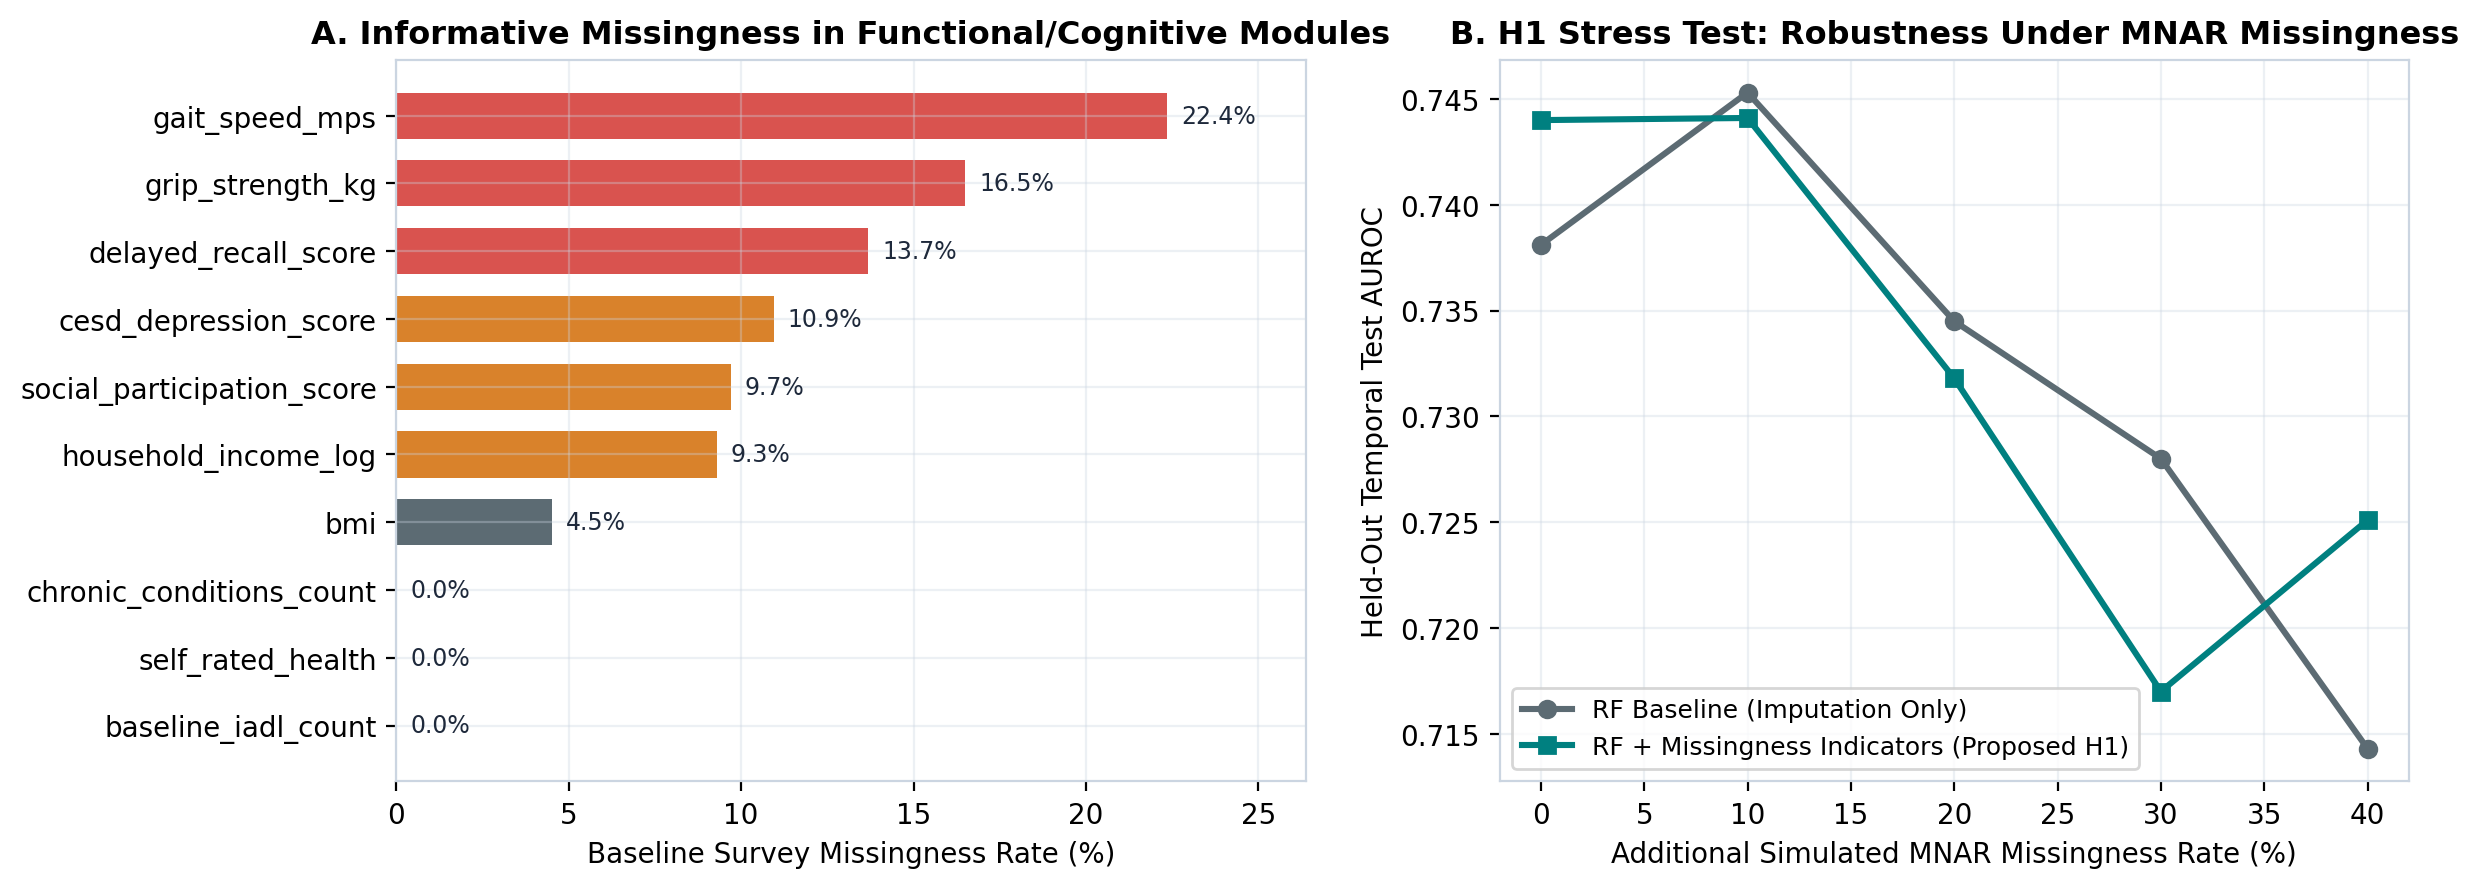

In [1]:
miss_df = summarize_missingness(cohort_df)
print(miss_df.to_string(index=False))


## 3. System Architecture & 2-Year MEXT Master's Roadmap
Below is the end-to-end leakage-safe architecture connecting Phase 1 (HRS computational pilot) to Phase 2 (Japanese JAGES validation during the 2-year Master's program).


Rendered Figure 6: AgeWell-AI System Architecture & 2-Year MEXT Master's Roadmap


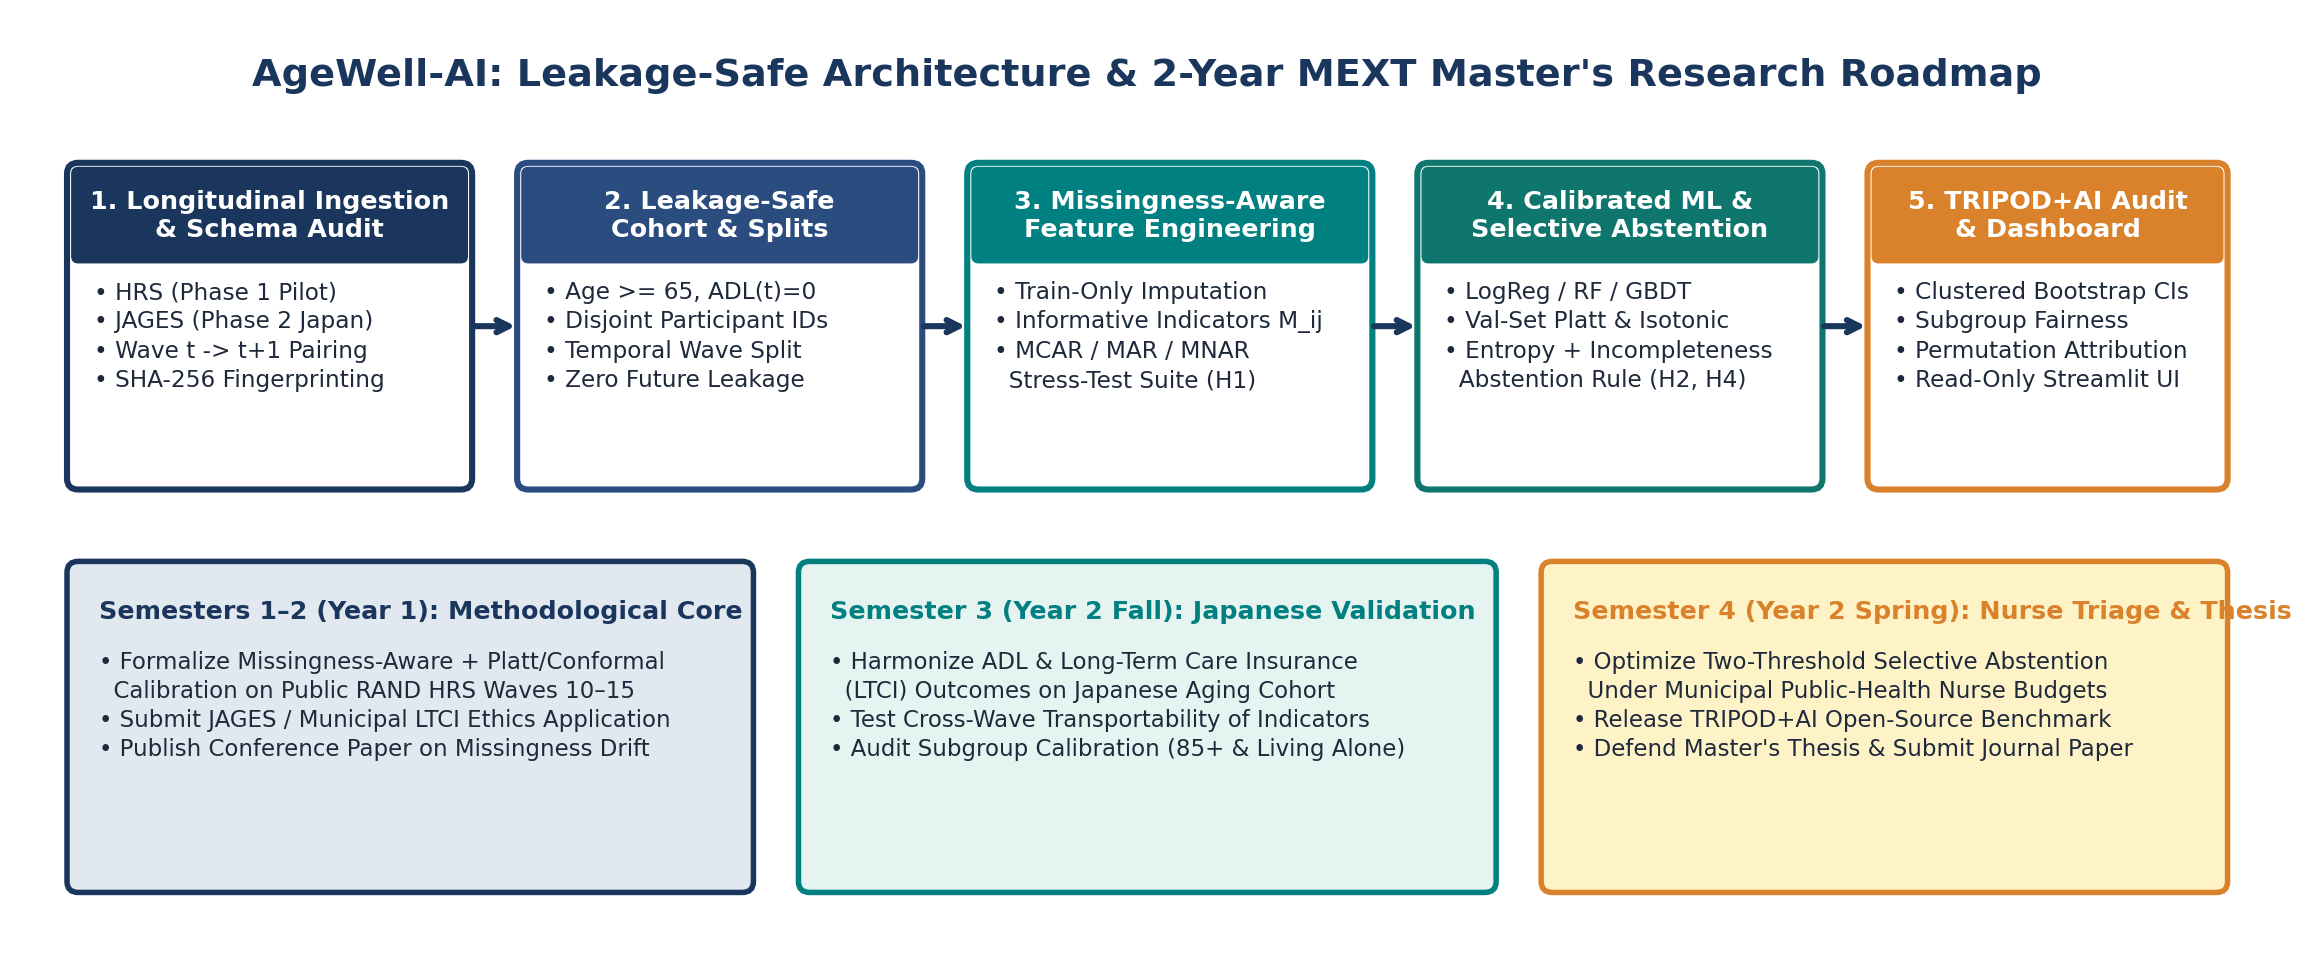

In [1]:
# Display AgeWell-AI System Architecture & MEXT Roadmap Diagram
from IPython.display import Image
Image('../reports/figures/fig6_system_architecture_and_roadmap.png')
